# 00_03 Joint, Marginal and Conditional Distributions; Independence and Correlation

**Learning objectives**
- Read a **joint distribution** of two variables, and derive **marginals** and **conditionals** from it.
- Define **independence**, **covariance** and **correlation**, and know what correlation does *not* tell you.
- Use the **bivariate Normal**: conditional mean, conditional variance and "regression to the mean".
- Solve a height-weight problem by hand, in code and by simulation; see 3D joint surfaces.

**Prerequisites:** [00_01 Random variables](00_01_random_variables.ipynb), [00_02 Expectation and moments](00_02_expectation_moments.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A random variable has a PMF/PDF and a CDF; $E[X]$ is its mean, $\mathrm{Var}(X)=E[X^2]-E[X]^2$.
- **Conditional probability:** $P(A\mid B)=\dfrac{P(A\cap B)}{P(B)}$ (the probability of $A$ once we know $B$ happened).
- The **Normal** distribution has mean $\mu$, SD $\sigma$, and $z=(x-\mu)/\sigma$.

## 3. Intuition and story

Real data come in **pairs or tuples**: height and weight, device and purchase, temperature and electricity demand. The **joint distribution** describes both variables together. From it we get:
- the **marginal** distribution of each variable alone (ignore the other),
- the **conditional** distribution of one given a value of the other ("what is the weight of people who are 185 cm tall?"),
- the **dependence** between them: **independent** if knowing one tells nothing about the other.

**Covariance** and **correlation** measure *linear* association. Taller people tend to be heavier, so their correlation is positive. But correlation 0 does not mean independence: $Y=X^2$ is completely determined by $X$ yet can have zero correlation (section 6).

## 4. Formal definition

For discrete $(X,Y)$: joint PMF $p(x,y)=P(X=x,Y=y)$. For continuous: joint PDF $f(x,y)$ with $P((X,Y)\in A)=\iint_Af$.

| Concept | Formula |
|---|---|
| Marginal | $p_X(x)=\sum_yp(x,y)$, $\quad f_X(x)=\int f(x,y)dy$ |
| Conditional | $p(y\mid x)=\dfrac{p(x,y)}{p_X(x)}$, $\quad f(y\mid x)=\dfrac{f(x,y)}{f_X(x)}$ |
| Independence | $p(x,y)=p_X(x)p_Y(y)$ for all $x,y$ (equivalently $f(y\mid x)=f_Y(y)$) |
| Covariance | $\mathrm{Cov}(X,Y)=E[(X-\mu_X)(Y-\mu_Y)]=E[XY]-E[X]E[Y]$ |
| Correlation | $\rho=\dfrac{\mathrm{Cov}(X,Y)}{\sigma_X\sigma_Y}\in[-1,1]$ |

**Bivariate Normal:** $(X,Y)$ with means $\mu_X,\mu_Y$, SDs $\sigma_X,\sigma_Y$ and correlation $\rho$; its density is a bell-shaped hill whose contours are ellipses.

## 5. Derivations

**Marginal from joint.** $P(X=x)=\sum_yP(X=x,Y=y)$ because the events $\{Y=y\}$ partition the sample space.

**Independent implies zero covariance.** If independent, $E[XY]=\sum\sum xy\,p_X(x)p_Y(y)=E[X]E[Y]$, so $\mathrm{Cov}=0$. The converse is false.

**Variance of a sum.** $\mathrm{Var}(X+Y)=\mathrm{Var}(X)+\mathrm{Var}(Y)+2\mathrm{Cov}(X,Y)$; for independent variables the covariance term vanishes.

**Correlation bounds.** For standardized variables $U,V$ with unit variance, $\mathrm{Var}(U\pm V)=2\pm2\rho\ge0$, so $-1\le\rho\le1$; $\rho=\pm1$ iff $Y$ is an exact linear function of $X$.

**Bivariate Normal conditionals.** Writing $Y=\mu_Y+\rho\frac{\sigma_Y}{\sigma_X}(X-\mu_X)+\varepsilon$ with $\varepsilon\sim N(0,\sigma_Y^2(1-\rho^2))$ independent of $X$ gives
$$Y\mid X=x\ \sim\ N\!\Big(\mu_Y+\rho\frac{\sigma_Y}{\sigma_X}(x-\mu_X),\ \ \sigma_Y^2(1-\rho^2)\Big).$$
The conditional mean is **linear in $x$** (this is simple linear regression), and the conditional variance is **smaller** than the marginal variance by the factor $1-\rho^2$ and does not depend on $x$. Check: $\mathrm{Cov}(X,Y)=\rho\frac{\sigma_Y}{\sigma_X}\mathrm{Var}(X)=\rho\sigma_X\sigma_Y$. ✓.

**Regression to the mean.** With $\rho<1$, the predicted $Y$ is fewer SDs from its mean than $x$ is from its own: tall parents have, on average, children who are tall but less extreme.

**In plain words.** Knowing $X$ shifts the best guess of $Y$ along a line and shrinks the uncertainty by $\sqrt{1-\rho^2}$.

## 6. Properties and relationships

- **Uncorrelated is not independent:** if $X$ is symmetric about 0 and $Y=X^2$, then $\mathrm{Cov}(X,Y)=E[X^3]-E[X]E[X^2]=0$, yet $Y$ is a function of $X$. For the bivariate **Normal** only, zero correlation does imply independence.
- **Correlation is not causation** and captures only *linear* association.
- **Marginals do not determine the joint:** different joints can share the same marginals (the dependence, a "copula", is separate: Module 03).
- **Linear transformations** change covariance: $\mathrm{Cov}(aX+b,cY+d)=ac\,\mathrm{Cov}(X,Y)$; correlation is unchanged (up to sign).

## 7. 2D visuals

### 7.1 A discrete joint table
Device (mobile or desktop) and purchase (yes or no): joint probabilities as a heat map, with the marginals on the sides.

           buy  no buy
mobile   0.012   0.588
desktop  0.016   0.384

marginal of device: {'mobile': 0.6, 'desktop': 0.4}  marginal of purchase: {'buy': 0.028, 'no buy': 0.972}


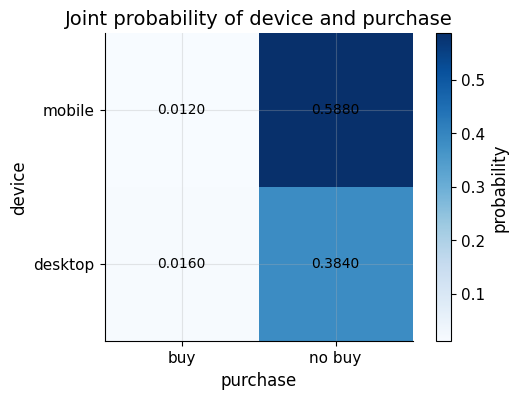

In [2]:
joint = pd.DataFrame([[0.6 * 0.02, 0.6 * 0.98], [0.4 * 0.04, 0.4 * 0.96]], index=["mobile", "desktop"], columns=["buy", "no buy"])
marginal_device = joint.sum(axis=1)
marginal_buy = joint.sum(axis=0)
print(joint.round(4)); print("\nmarginal of device:", marginal_device.round(3).to_dict(), " marginal of purchase:", marginal_buy.round(4).to_dict())

fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(joint.values, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(joint.columns)
ax.set_yticks([0, 1]); ax.set_yticklabels(joint.index)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{joint.values[i, j]:.4f}", ha="center", va="center", color="black")
ax.set_title("Joint probability of device and purchase")
ax.set_xlabel("purchase")
ax.set_ylabel("device")
plt.colorbar(image, label="probability")
plt.show()

### 7.2 The bivariate Normal: scatter and contours for different correlations
The contours are ellipses; rho tilts and narrows them.

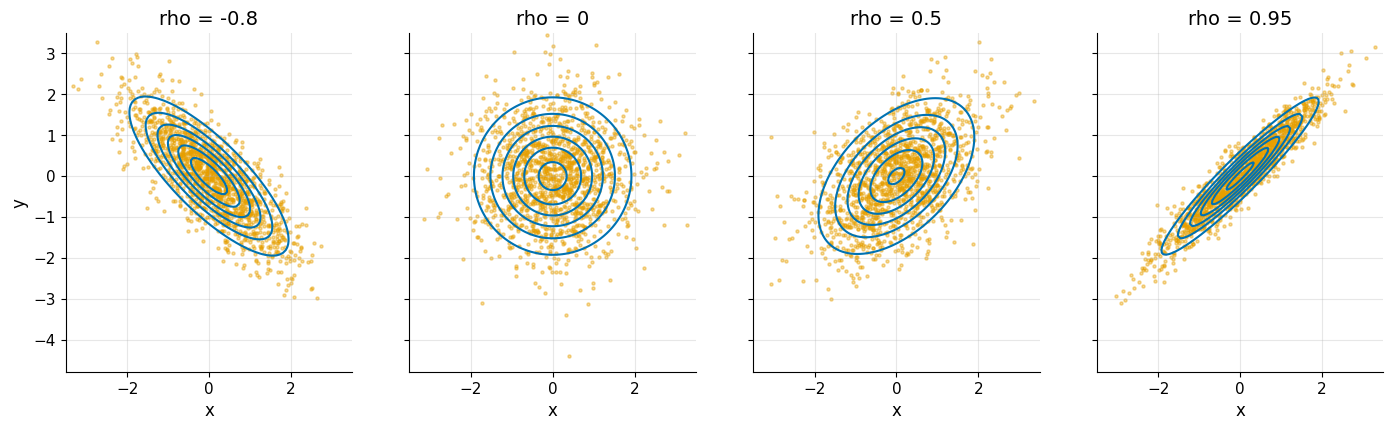

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), sharex=True, sharey=True)
for ax, rho in zip(axes, [-0.8, 0, 0.5, 0.95]):
    covariance = [[1, rho], [rho, 1]]
    points = rng.multivariate_normal([0, 0], covariance, size=1500)
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.4, color=SIM)
    grid = np.linspace(-3.5, 3.5, 100)
    G1, G2 = np.meshgrid(grid, grid)
    density = stats.multivariate_normal([0, 0], covariance).pdf(np.dstack([G1, G2]))
    ax.contour(G1, G2, density, levels=6, colors=MAIN)
    ax.set_title(f"rho = {rho}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.show()

### 7.3 Uncorrelated but dependent
Y = X squared is perfectly determined by X, yet the correlation is about 0.

correlation of X and X^2: 0.035


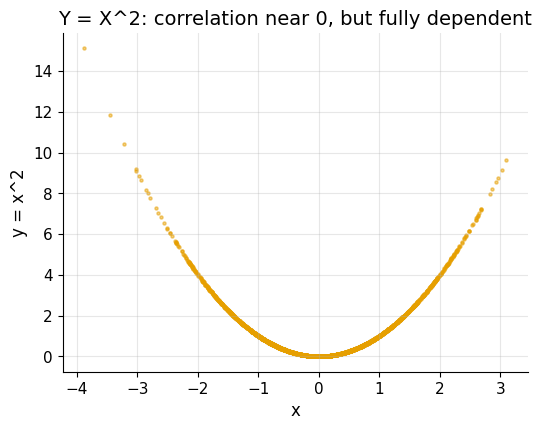

In [4]:
x = rng.normal(size=3000)
y = x**2
print("correlation of X and X^2:", round(np.corrcoef(x, y)[0, 1], 3))
fig, ax = plt.subplots(figsize=(6, 4.4))
ax.scatter(x, y, s=5, alpha=0.5, color=SIM)
ax.set_title("Y = X^2: correlation near 0, but fully dependent")
ax.set_xlabel("x")
ax.set_ylabel("y = x^2")
plt.show()

## 8. 3D visuals

### 8.1 Static: the bivariate Normal density surface (rho = 0.6)

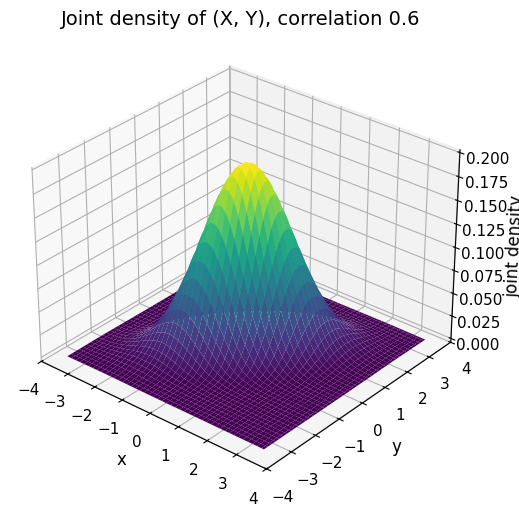

In [5]:
grid = np.linspace(-3.5, 3.5, 90)
G1, G2 = np.meshgrid(grid, grid)
density = stats.multivariate_normal([0, 0], [[1, 0.6], [0.6, 1]]).pdf(np.dstack([G1, G2]))
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(G1, G2, density, cmap="viridis", edgecolor="none")
ax.set_title("Joint density of (X, Y), correlation 0.6")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("joint density")
ax.view_init(elev=30, azim=-50)
plt.show()

### 8.2 Static: the joint PMF of two dice (max and min) as 3D bars

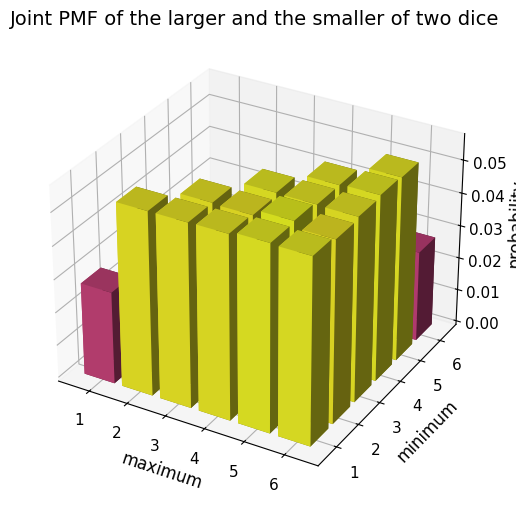

In [6]:
dice = rng.integers(1, 7, size=(500_000, 2))
maxima, minima = dice.max(axis=1), dice.min(axis=1)
table = np.zeros((6, 6))
for hi, lo in zip(maxima[:200_000], minima[:200_000]):
    table[hi - 1, lo - 1] += 1
table /= table.sum()
X6, Y6 = np.meshgrid(np.arange(1, 7), np.arange(1, 7), indexing="ij")
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.bar3d(X6.ravel() - 0.4, Y6.ravel() - 0.4, np.zeros(36), 0.8, 0.8, table.ravel(), color=plt.cm.plasma(table.ravel() / table.max()))
ax.set_title("Joint PMF of the larger and the smaller of two dice")
ax.set_xlabel("maximum")
ax.set_ylabel("minimum")
ax.set_zlabel("probability")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.3 Interactive Plotly version of 8.1

In [7]:
fig = go.Figure(go.Surface(x=grid, y=grid, z=density, colorscale="Viridis"))
fig.update_layout(title="Joint density of (X, Y), correlation 0.6", width=750, height=550,
                  scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="joint density"))
fig.show()

## 9. Simulation vs theory

### 9.1 Conditional mean and spread from simulated pairs
For rho = 0.6, simulate 300,000 pairs; among pairs with X near 1.5, the mean of Y should be rho x = 0.9 and the SD sqrt(1 - rho^2) = 0.8.

In [8]:
rho = 0.6
pairs = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=300_000)
near = np.abs(pairs[:, 0] - 1.5) < 0.05
print(f"given X near 1.5: mean of Y = {pairs[near, 1].mean():.3f} (theory {rho * 1.5:.3f}), SD of Y = {pairs[near, 1].std():.3f} (theory {np.sqrt(1 - rho**2):.3f})")
print(f"sample correlation {np.corrcoef(pairs.T)[0, 1]:.4f}, sample covariance {np.cov(pairs.T)[0, 1]:.4f}")

given X near 1.5: mean of Y = 0.881 (theory 0.900), SD of Y = 0.780 (theory 0.800)
sample correlation 0.6011, sample covariance 0.6015


### 9.2 The conditional mean is a straight line

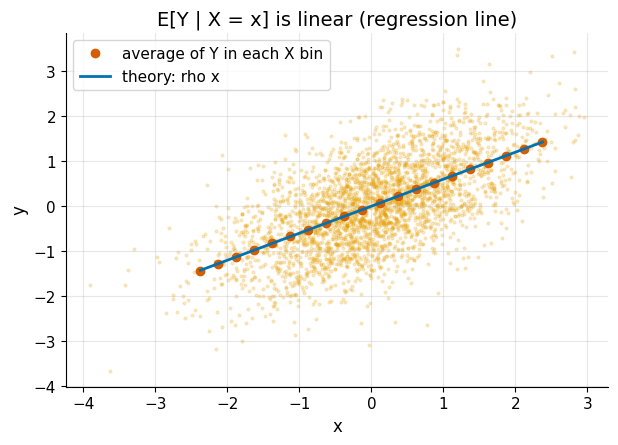

In [9]:
bins = np.linspace(-2.5, 2.5, 21)
centers = (bins[:-1] + bins[1:]) / 2
conditional_means = [pairs[(pairs[:, 0] >= a) & (pairs[:, 0] < b), 1].mean() for a, b in zip(bins[:-1], bins[1:])]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(pairs[:3000, 0], pairs[:3000, 1], s=4, alpha=0.2, color=SIM)
ax.plot(centers, conditional_means, "o", color=HIGHLIGHT, label="average of Y in each X bin")
ax.plot(centers, rho * centers, color=MAIN, linewidth=2, label="theory: rho x")
ax.set_title("E[Y | X = x] is linear (regression line)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

In [10]:
mvn = stats.multivariate_normal(mean=[170, 70], cov=[[64, 57.6], [57.6, 144]])
print("pdf at the mean       :", round(mvn.pdf([170, 70]), 6))
print("mean, cov             :", mvn.mean, mvn.cov.tolist())
print("rvs(2)                :", mvn.rvs(size=2, random_state=1).round(1).tolist())
print("cdf (both below)      :", round(mvn.cdf([175, 75]), 4))
print("correlation from cov  :", 57.6 / np.sqrt(64 * 144))
print("scipy.stats.pearsonr  :", np.round(stats.pearsonr(pairs[:5000, 0], pairs[:5000, 1]), 4))

pdf at the mean       : 0.002072
mean, cov             : [170.  70.] [[64.0, 57.6], [57.6, 144.0]]
rvs(2)                : [[163.2, 49.4], [178.8, 73.3]]
cdf (both below)      : 0.5672
correlation from cov  : 0.6
scipy.stats.pearsonr  : [0.6074 0.    ]


## 11. Real-world worked example: height and weight

**Scenario (illustrative numbers).** Adult height $H$ (cm) and weight $W$ (kg) are bivariate Normal with $\mu_H=170$, $\sigma_H=8$, $\mu_W=70$, $\sigma_W=12$ and correlation $\rho=0.6$.

**Questions**
1. What is the **covariance** of $H$ and $W$?
2. For people who are **185 cm** tall, what are the **mean and SD of weight**?
3. What is $P(W>85\mid H=185)$, and how does it compare with $P(W>85)$ for everyone?

### 11.1 By hand
**Q1.** $\mathrm{Cov}=\rho\sigma_H\sigma_W=0.6\times8\times12=57.6$.

**Q2.** Conditional mean $=70+0.6\cdot\frac{12}{8}(185-170)=70+0.9\times15=83.5$ kg. Conditional SD $=12\sqrt{1-0.36}=12\times0.8=9.6$ kg.

**Q3.** $z=\frac{85-83.5}{9.6}=0.156$, so $P(W>85\mid H=185)=1-\Phi(0.156)=0.438$. Unconditionally, $z=\frac{85-70}{12}=1.25$ and $P(W>85)=1-\Phi(1.25)=0.106$.

In [11]:
import math

mu_h, sd_h, mu_w, sd_w, rho = 170, 8, 70, 12, 0.6

def standard_normal_cdf(z):
    return 0.5 * (1 + math.erf(z / math.sqrt(2)))

covariance_hand = rho * sd_h * sd_w
cond_mean_hand = mu_w + rho * sd_w / sd_h * (185 - mu_h)
cond_sd_hand = sd_w * math.sqrt(1 - rho**2)
p_cond_hand = 1 - standard_normal_cdf((85 - cond_mean_hand) / cond_sd_hand)
p_marginal_hand = 1 - standard_normal_cdf((85 - mu_w) / sd_w)
print(f"Cov = {covariance_hand:.1f}, E[W | H=185] = {cond_mean_hand:.1f}, SD = {cond_sd_hand:.1f}, P(W>85 | H=185) = {p_cond_hand:.4f}, P(W>85) = {p_marginal_hand:.4f}")

Cov = 57.6, E[W | H=185] = 83.5, SD = 9.6, P(W>85 | H=185) = 0.4379, P(W>85) = 0.1056


### 11.2 In code with `scipy`, and the asserts

In [12]:
cov_matrix = [[sd_h**2, covariance_hand], [covariance_hand, sd_w**2]]
people = stats.multivariate_normal([mu_h, mu_w], cov_matrix)

# conditional distribution computed from the joint density: f(w | h) = f(h, w) / f_H(h), numerically over w
w_grid = np.linspace(20, 140, 6001)
joint_density = people.pdf(np.column_stack([np.full_like(w_grid, 185), w_grid]))
conditional_density = joint_density / np.trapezoid(joint_density, w_grid)
cond_mean_code = np.trapezoid(w_grid * conditional_density, w_grid)
cond_sd_code = np.sqrt(np.trapezoid((w_grid - cond_mean_code) ** 2 * conditional_density, w_grid))
p_cond_code = np.trapezoid(conditional_density[w_grid >= 85], w_grid[w_grid >= 85])
p_marginal_code = stats.norm(mu_w, sd_w).sf(85)

assert np.isclose(cond_mean_hand, cond_mean_code, atol=1e-3)
assert np.isclose(cond_sd_hand, cond_sd_code, atol=1e-3)
assert np.isclose(p_cond_hand, p_cond_code, atol=1e-4)
assert np.isclose(p_marginal_hand, p_marginal_code)
print(f"from the joint density: E[W | H=185] = {cond_mean_code:.2f}, SD = {cond_sd_code:.2f}, P(W>85 | H=185) = {p_cond_code:.4f}; P(W>85) = {p_marginal_code:.4f}")

from the joint density: E[W | H=185] = 83.50, SD = 9.60, P(W>85 | H=185) = 0.4379; P(W>85) = 0.1056


### 11.3 Verify by simulation

In [13]:
simulated = people.rvs(size=1_000_000, random_state=5)
tall = np.abs(simulated[:, 0] - 185) < 0.5
print(f"cov: exact {covariance_hand:.1f}, simulated {np.cov(simulated.T)[0, 1]:.1f}")
print(f"H near 185: mean W = {simulated[tall, 1].mean():.2f} (exact 83.5), SD = {simulated[tall, 1].std():.2f} (exact 9.6), P(W>85) = {np.mean(simulated[tall, 1] > 85):.4f} (exact {p_cond_hand:.4f})")
print(f"everyone: P(W>85) = {np.mean(simulated[:, 1] > 85):.4f} (exact {p_marginal_hand:.4f})")
assert abs(np.mean(simulated[tall, 1] > 85) - p_cond_hand) < 0.01

cov: exact 57.6, simulated 57.7


H near 185: mean W = 83.69 (exact 83.5), SD = 9.59 (exact 9.6), P(W>85) = 0.4464 (exact 0.4379)
everyone: P(W>85) = 0.1057 (exact 0.1056)


### 11.4 Plots

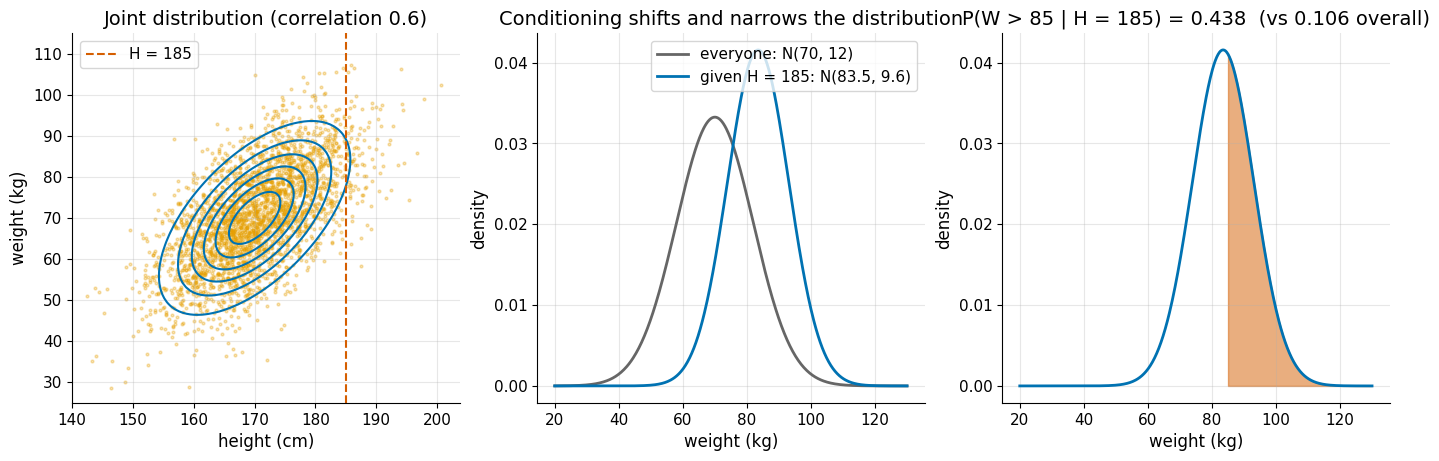

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sample = simulated[:3000]
axes[0].scatter(sample[:, 0], sample[:, 1], s=4, alpha=0.3, color=SIM)
h_grid, w_axis = np.meshgrid(np.linspace(140, 200, 100), np.linspace(25, 115, 100))
axes[0].contour(h_grid, w_axis, people.pdf(np.dstack([h_grid, w_axis])), levels=6, colors=MAIN)
axes[0].axvline(185, color=HIGHLIGHT, linestyle="--", label="H = 185")
axes[0].set_title(f"Joint distribution (correlation {rho})")
axes[0].set_xlabel("height (cm)")
axes[0].set_ylabel("weight (kg)")
axes[0].legend()

w_axis1 = np.linspace(20, 130, 500)
axes[1].plot(w_axis1, stats.norm(mu_w, sd_w).pdf(w_axis1), color=NEUTRAL, linewidth=2, label="everyone: N(70, 12)")
axes[1].plot(w_axis1, stats.norm(cond_mean_hand, cond_sd_hand).pdf(w_axis1), color=MAIN, linewidth=2, label="given H = 185: N(83.5, 9.6)")
axes[1].set_title("Conditioning shifts and narrows the distribution")
axes[1].set_xlabel("weight (kg)")
axes[1].set_ylabel("density")
axes[1].legend()

tail = w_axis1 > 85
axes[2].plot(w_axis1, stats.norm(cond_mean_hand, cond_sd_hand).pdf(w_axis1), color=MAIN, linewidth=2)
axes[2].fill_between(w_axis1[tail], stats.norm(cond_mean_hand, cond_sd_hand).pdf(w_axis1[tail]), color=HIGHLIGHT, alpha=0.5)
axes[2].set_title(f"P(W > 85 | H = 185) = {p_cond_hand:.3f}  (vs {p_marginal_hand:.3f} overall)")
axes[2].set_xlabel("weight (kg)")
axes[2].set_ylabel("density")
plt.show()

### 11.5 Interpretation and decision
- Height and weight have covariance **57.6** (correlation 0.6): taller people tend to be heavier.
- A person who is **185 cm** is expected to weigh **83.5 kg**, with an SD of **9.6 kg**, smaller than the 12 kg for everyone: knowing the height removes about 36 % of the variance ($\rho^2=0.36$).
- The chance of weighing more than 85 kg is **44 %** for a 185 cm person but only **11 %** overall. **Decision:** size products (seats, medication doses) by conditioning on height rather than on the overall weight distribution.
- Note the regression to the mean: 185 cm is 1.875 SD above average height, but the predicted weight (83.5) is only 1.125 SD above average weight.

### 11.6 Extra example: device and purchase (discrete)
Mobile visitors are 60 % of traffic and convert at 2 %; desktop visitors convert at 4 %. What is $P(\text{buy})$, $P(\text{mobile}\mid\text{buy})$, and are device and purchase independent?

In [15]:
p_mobile, conv_mobile, conv_desktop = 0.6, 0.02, 0.04
p_buy_hand = p_mobile * conv_mobile + (1 - p_mobile) * conv_desktop
p_mobile_given_buy_hand = p_mobile * conv_mobile / p_buy_hand
independent = np.isclose(conv_mobile, conv_desktop)
assert np.isclose(p_buy_hand, joint["buy"].sum())
assert np.isclose(p_mobile_given_buy_hand, joint.loc["mobile", "buy"] / joint["buy"].sum())
print(f"P(buy) = {p_buy_hand:.4f}; P(mobile | buy) = {p_mobile_given_buy_hand:.4f} (vs {p_mobile} of traffic); independent: {independent}")
visits = rng.uniform(size=1_000_000) < p_mobile
buys = rng.uniform(size=1_000_000) < np.where(visits, conv_mobile, conv_desktop)
print(f"simulation: P(buy) = {buys.mean():.4f}, P(mobile | buy) = {visits[buys].mean():.4f}")

P(buy) = 0.0280; P(mobile | buy) = 0.4286 (vs 0.6 of traffic); independent: False
simulation: P(buy) = 0.0280, P(mobile | buy) = 0.4281


**Interpretation.** Mobile is 60 % of visits but only **43 % of purchases**: device and purchase are **not independent** (conversion differs), so the conditional distribution of device given a purchase differs from its marginal. This reversal of conditioning ($P(\text{buy}\mid\text{mobile})$ versus $P(\text{mobile}\mid\text{buy})$) is exactly what Bayes' theorem handles in the next lesson.

## 12. Where it is used

### Statistics
- **Regression** is the conditional mean $E[Y\mid X]$; correlation and covariance matrices summarize multivariate data; independence assumptions justify likelihoods.

### Data science
- **Feature correlation** and multicollinearity checks, contingency tables, segmenting metrics by group (conditional distributions), copulas for dependence (Module 03).

### ML and AI
- **Joint and conditional models:** Naive Bayes (assumes conditional independence), Gaussian processes and multivariate Gaussians, generative models $p(x,y)=p(y)p(x\mid y)$, PCA diagonalizes the covariance matrix.

## 13. Common pitfalls and misconceptions

- **Zero correlation does not imply independence** (Y = X^2); it does for jointly Normal variables.
- **Correlation is not causation,** and it only detects linear relationships; plot the data.
- **P(A | B) is not P(B | A)** (mobile given buy versus buy given mobile).
- **Marginals do not determine the joint:** you cannot recover dependence from the two histograms.
- **Conditional SD does not depend on x** for the Normal, but it generally does for other joints.
- **Outliers can create or destroy correlation;** check robust measures (Spearman).

## 14. Exercises

1. For the joint table of devices and purchases in 7.1, compute $P(\text{desktop}\mid\text{no buy})$.
2. Two variables have $\sigma_X=3$, $\sigma_Y=5$, $\mathrm{Cov}=6$. Find $\rho$ and $\mathrm{Var}(X+Y)$ and $\mathrm{Var}(X-Y)$.
3. For the height-weight model, find the mean weight of people 155 cm tall and compare it with the overall mean 70.
4. Show that $Y=X^2$ with $X\sim N(0,1)$ has $\mathrm{Cov}(X,Y)=0$.
5. (Harder) A bivariate Normal has $\rho=0.8$. What proportion of the variance of $Y$ is explained by $X$, and what is the conditional SD as a fraction of $\sigma_Y$?

Solutions are at the end.

## 15. Summary table

| Concept | Formula | `scipy` / `numpy` |
|---|---|---|
| Marginal | sum or integrate out the other variable | `table.sum(axis=...)` |
| Conditional | joint / marginal | divide |
| Independence | joint = product of marginals | compare |
| Covariance | E[XY] - E[X]E[Y] | `np.cov` |
| Correlation | Cov / (SD SD) | `np.corrcoef`, `stats.pearsonr` |
| Bivariate Normal conditional | N(mu_y + rho sd_y/sd_x (x - mu_x), sd_y^2 (1 - rho^2)) | `stats.multivariate_normal` |

## Solutions

In [16]:
print("1: P(desktop | no buy) =", round(joint.loc["desktop", "no buy"] / joint["no buy"].sum(), 4))
rho2 = 6 / (3 * 5)
print("2: rho =", rho2, " Var(X+Y) =", 9 + 25 + 2 * 6, " Var(X-Y) =", 9 + 25 - 2 * 6)
print("3: E[W | H = 155] =", 70 + 0.6 * 12 / 8 * (155 - 170))
print("4: correlation of X and X^2 in a simulation:", round(np.corrcoef(x, x**2)[0, 1], 3))
print("5: R^2 =", 0.8**2, " conditional SD / sigma_Y =", round(np.sqrt(1 - 0.8**2), 3))

1: P(desktop | no buy) = 0.3951
2: rho = 0.4  Var(X+Y) = 46  Var(X-Y) = 22
3: E[W | H = 155] = 56.5
4: correlation of X and X^2 in a simulation: 0.035
5: R^2 = 0.6400000000000001  conditional SD / sigma_Y = 0.6


**1.** $P(\text{desktop}\mid\text{no buy})=\dfrac{0.4\times0.96}{0.6\times0.98+0.4\times0.96}=0.395$.

**2.** $\rho=6/15=0.4$; $\mathrm{Var}(X+Y)=9+25+12=46$; $\mathrm{Var}(X-Y)=9+25-12=22$.

**3.** $70+0.9\times(-15)=56.5$ kg: below the overall mean, by less than the height gap suggests.

**4.** $\mathrm{Cov}(X,X^2)=E[X^3]-E[X]E[X^2]=0-0=0$ because odd moments of a symmetric variable vanish.

**5.** $\rho^2=0.64$: $X$ explains 64 % of the variance of $Y$; the conditional SD is $\sqrt{1-0.64}=0.6\,\sigma_Y$.